# Olist marketplace: SQL product analytics

Author: Anastasia Kalugina

## 1. Goal

Answer 11 business questions about a Brazilian online marketplace using SQL only
(DuckDB, with a PostgreSQL-compatible subset), then turn the tables into
business conclusions. Every question lives in its own file in `sql/olist/`.

The notebook is read top to bottom: a question, the query result, a short
takeaway. All numbers in the text come from the outputs above them.

## 2. Data

Olist Brazilian E-Commerce Public Dataset, 9 tables, about 100k orders placed
in 2016-2018 (Kaggle, licence CC BY-NC-SA 4.0; see `DATA_LICENSE.md`).
The data is not stored in this repository: `python -m pa.data download` fetches it.

Relations between the tables:

```mermaid
erDiagram
    customers ||--o{ orders : "customer_id"
    orders ||--|{ order_items : "order_id"
    orders ||--o{ order_payments : "order_id"
    orders ||--o{ order_reviews : "order_id"
    products ||--o{ order_items : "product_id"
    sellers ||--o{ order_items : "seller_id"
    products }o--|| category_translation : "category name"
```

**The main trap.** `customer_id` is created per order. The real person is
`customer_unique_id`. Counting customers by `customer_id` makes every buyer look
new on every purchase. All queries below use `customer_unique_id`.

Setup: imports, the database connection, a fixed seed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))

from pa import config  # noqa: E402
from pa.db import connect, run_sql  # noqa: E402

SEED = config.SEED
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}".rstrip("0").rstrip("."))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

if not config.OLIST_DB.exists():
    raise SystemExit("Run `python -m pa.data download` and `python -m pa.data build`")
con = connect(config.OLIST_DB, read_only=True)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("tables:", [r[0] for r in con.execute("SHOW TABLES").fetchall()])

tables: ['category_translation', 'customers', 'geolocation', 'order_items', 'order_payments', 'order_reviews', 'order_value', 'orders', 'orders_enriched', 'orders_window', 'products', 'sales_orders', 'sellers']


## 3. Data quality and EDA

### Q1. Can we trust the data?
File: [`sql/olist/01_data_quality.sql`](../sql/olist/01_data_quality.sql).
The query returns row counts, keys that occur more than once, rows with a missing
parent, and orders per month. The last part decides which months we analyse.

In [2]:
dq = run_sql(con, "olist/01_data_quality")
for section in ["rows", "duplicate_keys", "orphans"]:
    print(section)
    print(
        dq[dq.section == section]
        .drop(columns="section")
        .to_string(index=False, header=False)
    )
    print()

rows
category_translation      71
           customers   99441
         geolocation 1000163
         order_items  112650
      order_payments  103886
       order_reviews   99224
              orders   99441
            products   32951
             sellers    3095

duplicate_keys
                       customers.customer_id   0
        order_items(order_id, order_item_id)   0
order_payments(order_id, payment_sequential)   0
                     order_reviews.review_id 789
                             orders.order_id   0
                         products.product_id   0
                           sellers.seller_id   0

orphans
   order_items -> orders 0
 order_items -> products 0
  order_items -> sellers 0
order_payments -> orders 0
 order_reviews -> orders 0
     orders -> customers 0



The `orders_per_month` rows of Q1 as a series, to read the edges.

In [3]:
per_month = dq[dq.section == "orders_per_month"].set_index("check_name")["value"]
print(per_month.to_string())

check_name
2016-09-01       4
2016-10-01     324
2016-12-01       1
2017-01-01     800
2017-02-01    1780
2017-03-01    2682
2017-04-01    2404
2017-05-01    3700
2017-06-01    3245
2017-07-01    4026
2017-08-01    4331
2017-09-01    4285
2017-10-01    4631
2017-11-01    7544
2017-12-01    5673
2018-01-01    7269
2018-02-01    6728
2018-03-01    7211
2018-04-01    6939
2018-05-01    6873
2018-06-01    6167
2018-07-01    6292
2018-08-01    6512
2018-09-01      16
2018-10-01       4


The same series as a bar chart, to see the thin edge months at a glance.

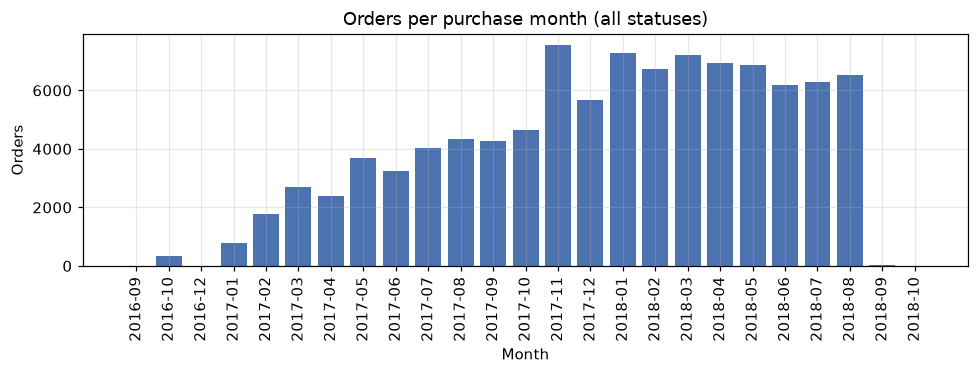

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(per_month.index.str[:7], per_month.values, color="#4c72b0")
ax.set_title("Orders per purchase month (all statuses)")
ax.set_xlabel("Month")
ax.set_ylabel("Orders")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()

**Takeaway.** No orphan rows and no duplicate order, customer, product or seller
keys. One exception: `review_id` is not unique (789 values appear more than once),
so reviews are always averaged per order before joining. Customers: 99,441 rows
are `customer_id`s but only 96,096 are real people (checked below).

The edges are thin: Sep-Dec 2016 has 4, 324, 0 and 1 orders, Sep-Oct 2018 has 16
and 4. Monthly growth rates there would be noise. **Analysis window: purchases from
2017-01-01 to 2018-08-31** (set once in `sql/schema/olist_views.sql`).

In [5]:
trap = con.execute(
    """
    SELECT COUNT(*) AS customer_id_rows,
           COUNT(DISTINCT customer_unique_id) AS real_people
    FROM customers
    """
).df()
multi = con.execute(
    """
    SELECT COUNT(*) AS people_with_several_customer_ids
    FROM (
        SELECT customer_unique_id FROM customers
        GROUP BY customer_unique_id HAVING COUNT(*) > 1
    ) AS t
    """
).df()
window = con.execute(
    "SELECT (SELECT COUNT(*) FROM orders_window) AS orders_in_window, "
    "(SELECT COUNT(*) FROM sales_orders) AS sales_orders"
).df()
print(trap.to_string(index=False))
print(multi.to_string(index=False))
print(window.to_string(index=False))

 customer_id_rows  real_people
            99441        96096
 people_with_several_customer_ids
                             2997
 orders_in_window  sales_orders
            99092         97905


**Takeaway.** 2,997 people have more than one `customer_id`: these are exactly the
repeat buyers that a naive count would miss. `sales_orders` (the base for most
queries) are window orders that are not canceled or unavailable and have at least
one item.

## 4. Main part: 11 questions

### Q2. How big is the business and how fast does it grow?
File: [`sql/olist/02_monthly_kpi.sql`](../sql/olist/02_monthly_kpi.sql).
GMV (price plus freight), orders, buyers and AOV per month, with month-over-month
change from `LAG`.

In [6]:
kpi = run_sql(con, "olist/02_monthly_kpi")
kpi["month"] = pd.to_datetime(kpi["month"]).dt.strftime("%Y-%m")
kpi

,month,orders,buyers,gmv,aov,gmv_mom,orders_mom
0,2017-01,787,753,"136,943.46",174.0069,NaN,NaN
1,2017-02,1718,1693,"283,561.69",165.0534,1.0706,1.183
2,2017-03,2617,2577,"425,617.96",162.6358,0.501,0.5233
3,2017-04,2377,2345,"405,848.61",170.7398,-0.0464,-0.0917
4,2017-05,3640,3569,"582,710.83",160.0854,0.4358,0.5313
5,2017-06,3205,3142,"499,652.24",155.8977,-0.1425,-0.1195
6,2017-07,3946,3872,"578,753.73",146.6685,0.1583,0.2312
7,2017-08,4272,4191,"661,903.52",154.94,0.1437,0.0826
8,2017-09,4227,4154,"717,102.72",169.6481,0.0834,-0.0105
9,2017-10,4547,4481,"764,756.03",168.1891,0.0665,0.0757


Chart: GMV per month (top) and average order value (bottom).

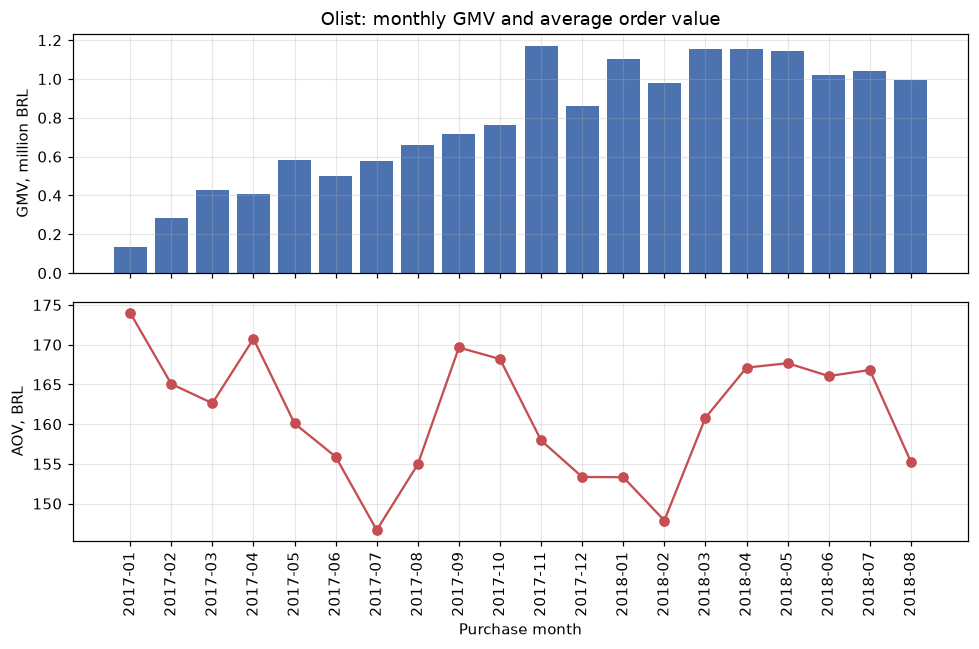

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].bar(kpi["month"], kpi["gmv"] / 1e6, color="#4c72b0")
axes[0].set_title("Olist: monthly GMV and average order value")
axes[0].set_ylabel("GMV, million BRL")
axes[1].plot(kpi["month"], kpi["aov"], marker="o", color="#c44e52")
axes[1].set_ylabel("AOV, BRL")
axes[1].set_xlabel("Purchase month")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "olist_monthly_gmv_aov.png", dpi=130)
plt.show()

**Takeaway.** GMV grows from 0.14M BRL in Jan 2017 to a peak of 1.17M in Nov 2017
(+53% on Oct), drops 26.5% in Dec, and in 2018 stays flat at roughly 1.0-1.16M a
month. AOV barely moves (147-174 BRL), so growth came from the number of orders,
not from bigger baskets. Buyers are almost equal to orders every month: people
rarely buy twice in the same month.

### Q3. Where do orders drop out of the funnel?
File: [`sql/olist/03_order_funnel.sql`](../sql/olist/03_order_funnel.sql).
A stage counts as reached when its timestamp is filled. Medians are hours since the
previous stage.

In [8]:
funnel = run_sql(con, "olist/03_order_funnel")
funnel

,step,stage,orders,share_of_purchased,median_hours_from_prev
0,1,purchased,99092,1,NaN
1,2,approved,98957,0.9986,0.3419
2,3,handed_to_carrier,97376,0.9827,43.4707
3,4,delivered,96204,0.9709,170.495
4,5,canceled,580,0.0059,NaN
5,6,unavailable,602,0.0061,NaN


**Takeaway.** The funnel is healthy: 99.86% of orders are approved, 97.09% are
delivered, 0.59% are canceled and 0.61% marked unavailable. Approval takes about
20 minutes at the median, handing over to the carrier 43.5 hours, delivery 170.5
hours (about 7 days). The time, not the loss, is the weak part: see Q4.

### Q4. How often is delivery late, and what does it cost in reviews?
File: [`sql/olist/04_delivery_sla.sql`](../sql/olist/04_delivery_sla.sql).
Late means delivered on a later date than promised. Review scores are averaged per
order first. Row `ALL` is the total.

In [9]:
sla = run_sql(con, "olist/04_delivery_sla")
sla_total = sla[sla.state == "ALL"]
sla_states = sla[(sla.state != "ALL") & (sla.delivered_orders >= 300)]
print(sla_total.to_string(index=False))
print()
print("Worst 5 and best 5 states with at least 300 delivered orders")
print(
    pd.concat(
        [
            sla_states.sort_values("late_share", ascending=False).head(5),
            sla_states.sort_values("late_share").head(5),
        ]
    ).to_string(index=False)
)

state  delivered_orders  late_orders  late_share  avg_score_on_time  avg_score_late
  ALL             96203         6531      0.0679             4.2914           2.272

Worst 5 and best 5 states with at least 300 delivered orders
state  delivered_orders  late_orders  late_share  avg_score_on_time  avg_score_late
   AL               396           85      0.2146             4.3055          2.1341
   MA               713          125      0.1753             4.1729          2.1803
   SE               332           51      0.1536             4.2491            1.94
   PI               475           66      0.1389             4.2716          2.2615
   CE              1273          176      0.1383             4.2397          2.0402
   PR              4903          199      0.0406             4.3056          2.6753
   SP             40399         1817       0.045             4.3261          2.5494
   MG             11319          519      0.0459             4.2797          2.3644
   DF         

**Takeaway.** 6.79% of delivered orders (6,531 of 96,203) arrive after the promised
date. Those orders get an average review of 2.27 against 4.29 for on-time ones.
Late share is 4.5% in Sao Paulo (SP) but 21.5% in Alagoas (AL), 17.5% in Maranhao
(MA) and 15.4% in Sergipe (SE). Late delivery is associated with bad reviews; this
data cannot prove it is the only cause, because late orders may differ in other
ways too.

### Q5. Which categories bring the most revenue each quarter?
File: [`sql/olist/05_top_categories.sql`](../sql/olist/05_top_categories.sql).
Top 3 by items revenue per quarter with `ROW_NUMBER`. The last quarter has only
July and August.

In [10]:
top = run_sql(con, "olist/05_top_categories")
top["quarter"] = pd.to_datetime(top["quarter"]).dt.strftime("%Y-Q") + (
    (pd.to_datetime(top["quarter"]).dt.month - 1) // 3 + 1
).astype(str)
print(top.to_string(index=False))
n_q = top["quarter"].nunique()
hb = top[top.category == "health_beauty"]["quarter"].nunique()
print(f"\nhealth_beauty is in the top 3 in {hb} of {n_q} quarters")

quarter  rank_in_quarter              category    revenue  orders  share_of_quarter
2017-Q1                1         health_beauty  61,327.46     429            0.0836
2017-Q1                2       furniture_decor  57,879.15     621            0.0789
2017-Q1                3        sports_leisure  52,774.27     369             0.072
2017-Q2                1 computers_accessories 101,954.52     596            0.0792
2017-Q2                2         health_beauty 101,546.36     680            0.0789
2017-Q2                3            cool_stuff  93,266.05     550            0.0725
2017-Q3                1        bed_bath_table 173,379.38    1420            0.1031
2017-Q3                2         health_beauty 136,121.78     981            0.0809
2017-Q3                3        sports_leisure 129,066.29    1130            0.0767
2017-Q4                1         watches_gifts 233,247.73    1059            0.0969
2017-Q4                2        bed_bath_table  185,876.5    1741           

**Takeaway.** `health_beauty` is in the top 3 in all 7 quarters; the leader changes
(computers_accessories, bed_bath_table, watches_gifts), but no category takes more
than about 13% of a quarter. Revenue is spread across categories, so there is no
single product line to depend on or to bet on.

### Q6. Do customers come back? Cohort retention
File: [`sql/olist/06_cohort_retention.sql`](../sql/olist/06_cohort_retention.sql).
Cohort = month of the first purchase of a `customer_unique_id`; the table shows the
share of the cohort that buys again in month 1 ... 6. Cells that lie after the end
of the data (Aug 2018) are masked, not shown as zero.

In [11]:
coh = run_sql(con, "olist/06_cohort_retention")
coh["cohort_month"] = pd.to_datetime(coh["cohort_month"])
retention = coh.pivot(
    index="cohort_month", columns="month_number", values="retention"
).fillna(0.0)
last_month = pd.Timestamp("2018-08-01")
for k in retention.columns:
    too_late = retention.index + pd.DateOffset(months=int(k)) > last_month
    retention.loc[too_late, k] = np.nan
retention.index = retention.index.strftime("%Y-%m")
cohort_size = coh[coh.month_number == 0].set_index("cohort_month")["cohort_size"]

pooled = (
    coh.groupby("month_number")[["active_customers", "cohort_size"]]
    .sum()
    .assign(retention=lambda d: d.active_customers / d.cohort_size)
)
print(pooled["retention"].to_string())
observed = retention.drop(columns=0).stack(future_stack=True).dropna()
print(f"\nobserved cohort-month cells: {len(observed)}")
print(f"min {observed.min():.2%}, max {observed.max():.2%}")

month_number
0        1
1   0.0048
2   0.0034
3   0.0026
4   0.0026
5   0.0022
6   0.0023

observed cohort-month cells: 99
min 0.09%, max 0.71%


Heatmap of retention for months 1-6; masked cells are not observable yet.

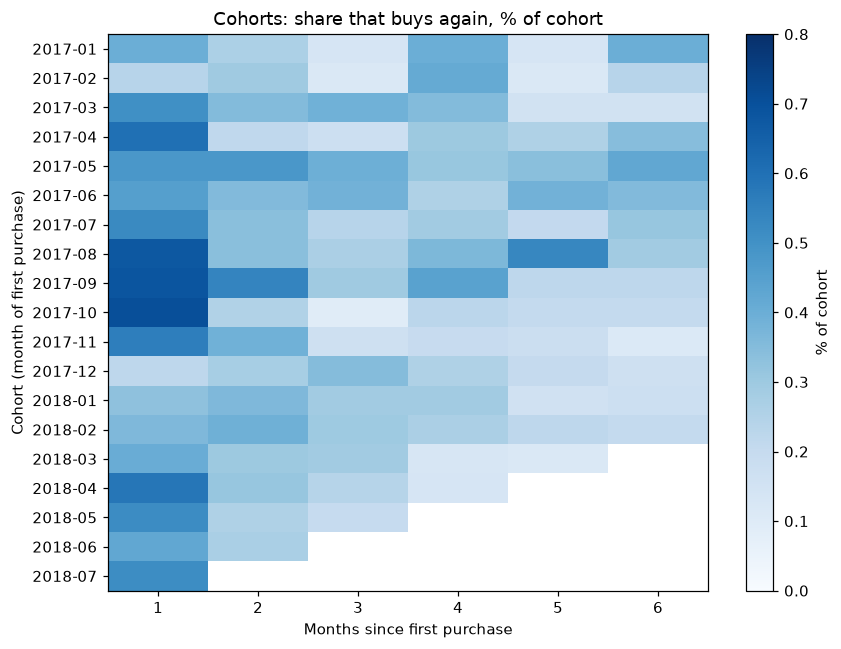

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
shown = retention.drop(columns=0).dropna(how="all") * 100
im = ax.imshow(shown.values, cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(shown.shape[1]), labels=shown.columns)
ax.set_yticks(range(shown.shape[0]), labels=shown.index)
ax.set_title("Cohorts: share that buys again, % of cohort")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (month of first purchase)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of cohort")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "olist_cohort_retention.png", dpi=130)
plt.show()

Caveat: the window starts in 2017-01, so people who bought in 2016 look like
"new" customers in the early 2017 cohorts (and in Q7). The effect is small
(about 330 orders in late 2016) but it slightly overstates new customers.

**Takeaway.** Month-1 retention is 0.48% over all cohorts and month-6 is 0.23%;
no observed cohort-month cell is above 0.71%. This is a "buy once" marketplace, so
the heatmap is nearly empty. That is a finding, not a bug: with `customer_id` instead
of `customer_unique_id` retention would be exactly zero, because every order gets a
new `customer_id`.

### Q7. How many customers buy a second time, and how fast?
File: [`sql/olist/07_repeat_purchase.sql`](../sql/olist/07_repeat_purchase.sql).
Share of customers with 2 or more orders; days from the first to the second order
(`LEAD`).

In [13]:
rep = run_sql(con, "olist/07_repeat_purchase")
for key, value in rep.iloc[0].items():
    print(f"{key:>18}: {value:,.4f}".rstrip("0").rstrip("."))
print(f"\n25th percentile in minutes: {rep.p25_days.iloc[0] * 24 * 60:.1f}")

         customers: 94,703
  repeat_customers: 2,874
      repeat_share: 0.0303
        max_orders: 16
          p25_days: 0.0013
       median_days: 28.0385
          p75_days: 123.868

25th percentile in minutes: 1.8


**Takeaway.** Only 3.03% of 94,703 customers (2,874) placed a second order, at most
16 orders. Half of the second orders come within 28 days, but the lower quartile is
under 2 minutes: a part of "repeat purchases" are probably one shopping session split
into several orders, not a return visit. True return rate is lower than 3%.

### Q8. Who are the valuable customers? RFM
File: [`sql/olist/08_rfm.sql`](../sql/olist/08_rfm.sql).
Recency and monetary value are scored with `NTILE(5)`. Frequency is not: nearly
everyone has one order, so quintiles would split identical customers at random;
a manual 1/2/3+ score is used instead.

In [14]:
rfm = run_sql(con, "olist/08_rfm")
print(rfm.to_string(index=False))
big = rfm[rfm.segment.isin(["new big spenders", "lost big spenders"])]
print(
    f"\nBig-spender segments: {big.customer_share.sum():.1%} of customers, "
    f"{big.revenue_share.sum():.1%} of revenue"
)

          segment  customers  customer_share      revenue  revenue_share  avg_gmv  avg_recency_days
 new big spenders      14599          0.1542 4,423,635.01         0.2821 303.0095           92.3397
lost big spenders      13959          0.1474 4,310,044.53         0.2748 308.7646          392.6786
       in between      18329          0.1935 2,787,384.58         0.1777 152.0751          220.5547
             lost      22890          0.2417 1,665,088.35         0.1062   72.743          394.6479
              new      22052          0.2329 1,611,326.25         0.1027  73.0694           90.4465
    lapsed repeat       1645          0.0174   490,875.16         0.0313 298.4044          320.8466
    active repeat       1229           0.013   395,352.86         0.0252 321.6866           89.3569

Big-spender segments: 30.2% of customers, 55.7% of revenue


**Takeaway.** Two big-spender segments (about 300 BRL per customer) make up 30.2%
of customers and 55.7% of revenue. The "lost big spenders" segment (14.7% of customers, 27.5% of
revenue) last bought 393 days before the end of the data on average. Active repeat buyers are 1.3% of customers and 2.5%
of revenue, too few to carry the business. Win-back of past big spenders is the
natural target.

### Q9. How concentrated is the seller base? Pareto
File: [`sql/olist/09_seller_pareto.sql`](../sql/olist/09_seller_pareto.sql).
Sellers ranked by items revenue with the cumulative revenue share.

In [15]:
pareto = run_sql(con, "olist/09_seller_pareto")
k80 = int((pareto.cum_revenue_share >= 0.8).idxmax())
print(f"sellers: {len(pareto)}")
print(f"sellers giving 80% of revenue: {k80 + 1} ({pareto.cum_seller_share[k80]:.1%})")
for n in (1, 10, 100, 300):
    print(f"top {n:>3} sellers: {pareto.cum_revenue_share[n - 1]:.1%} of revenue")

sellers: 3029
sellers giving 80% of revenue: 537 (17.7%)
top   1 sellers: 1.7% of revenue
top  10 sellers: 13.2% of revenue
top 100 sellers: 45.3% of revenue
top 300 sellers: 67.2% of revenue


Pareto curve: cumulative revenue share against the share of sellers.

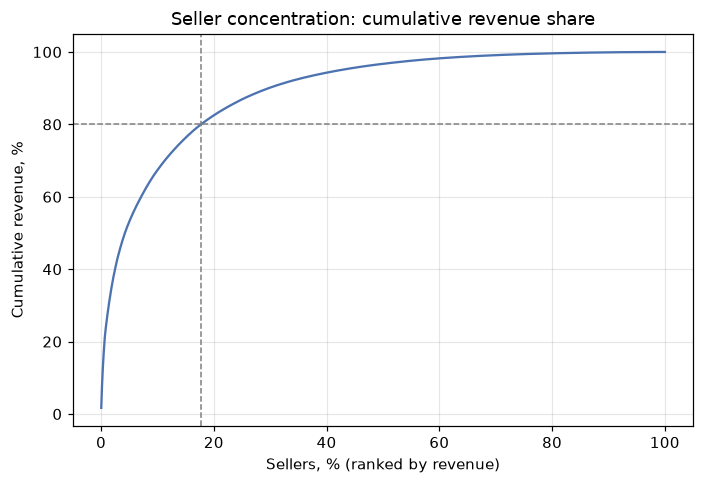

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(pareto.cum_seller_share * 100, pareto.cum_revenue_share * 100, color="#4c72b0")
ax.axhline(80, color="grey", ls="--", lw=1)
ax.axvline(pareto.cum_seller_share[k80] * 100, color="grey", ls="--", lw=1)
ax.set_title("Seller concentration: cumulative revenue share")
ax.set_xlabel("Sellers, % (ranked by revenue)")
ax.set_ylabel("Cumulative revenue, %")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "olist_seller_pareto.png", dpi=130)
plt.show()

**Takeaway.** 537 of 3,029 sellers (17.7%) bring 80% of revenue, the top 10 only
13.2%. It is a classic Pareto, but without a single dominant seller: losing one
top seller costs under 2% of revenue.

### Q10. What does Black Friday look like? 7-day moving average
File: [`sql/olist/10_rolling_orders.sql`](../sql/olist/10_rolling_orders.sql).
Daily orders and their 7-day moving average (a `RANGE` window over dates; missing
days count as zero).

In [17]:
roll = run_sql(con, "olist/10_rolling_orders")
roll["day"] = pd.to_datetime(roll["day"])
peak = roll.loc[roll.orders.idxmax()]
before = roll[roll.day == peak.day - pd.Timedelta(days=1)].iloc[0]
print(f"busiest day: {peak.day.date()} with {int(peak.orders)} orders")
print(f"day before: {int(before.orders)} orders, 7-day average {before.orders_ma7:.1f}")
print(f"peak day vs the day before: x{peak.orders / before.orders:.1f}")
vs_avg = peak.orders / before.orders_ma7
print(f"peak day vs the 7-day average of the day before: x{vs_avg:.1f}")
ma_peak = roll.loc[roll.orders_ma7.idxmax()]
print(f"highest 7-day average: {ma_peak.orders_ma7:.1f} on {ma_peak.day.date()}")

busiest day: 2017-11-24 with 1176 orders
day before: 283 orders, 7-day average 206.6
peak day vs the day before: x4.2
peak day vs the 7-day average of the day before: x5.7
highest 7-day average: 493.6 on 2017-11-29


Daily orders with the 7-day average; the annotation marks the peak day.

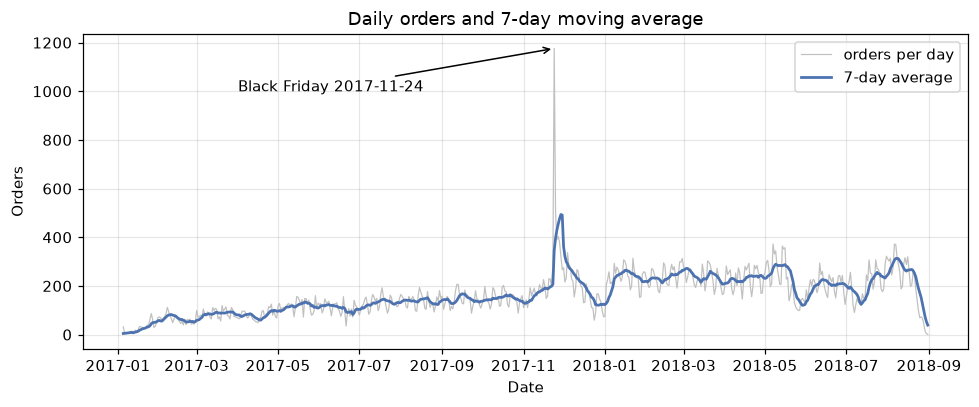

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(roll.day, roll.orders, color="#c0c0c0", lw=0.8, label="orders per day")
ax.plot(roll.day, roll.orders_ma7, color="#4c72b0", lw=1.8, label="7-day average")
ax.annotate(
    "Black Friday 2017-11-24",
    xy=(peak.day, peak.orders),
    xytext=(pd.Timestamp("2017-04-01"), 1000),
    arrowprops={"arrowstyle": "->"},
)
ax.set_title("Daily orders and 7-day moving average")
ax.set_xlabel("Date")
ax.set_ylabel("Orders")
ax.legend()
fig.tight_layout()
plt.show()

Note: Q10 counts all orders by purchase date, including canceled ones.

**Takeaway.** The peak is 2017-11-24, Black Friday: 1,176 orders, 4.2 times the
day before and 5.7 times the weekly average that preceded it. The moving average
keeps rising for days afterwards (493.6 on Nov 29), so demand stays elevated for
about a week, which matters for warehouse and carrier planning.

### Q11. How do people pay?
File: [`sql/olist/11_payments.sql`](../sql/olist/11_payments.sql).
Payment types, installment buckets (by the maximum number of installments in the
order) and orders paid with several methods. `avg_order_value` is the average total
paid in the bucket; an order paid by two types appears in both type rows.

In [19]:
pay = run_sql(con, "olist/11_payments")
pay

,dimension,bucket,orders,avg_order_value,share_of_orders
0,installments,1,47494,120.4524,0.4851
1,installments,2-3,22485,135.6946,0.2297
2,installments,4-6,15966,182.2345,0.1631
3,installments,7-10,11624,334.079,0.1187
4,installments,11+,336,362.2517,0.0034
5,methods_per_order,1,95699,160.4832,0.9775
6,methods_per_order,2+,2206,148.8623,0.0225
7,payment_type,credit_card,75387,165.7565,0.77
8,payment_type,boleto,19477,144.6527,0.1989
9,payment_type,voucher,3734,131.0384,0.0381


**Takeaway.** Credit cards appear in 77.0% of orders, boleto in 19.9%. Half of the
orders (48.5%) are paid in one installment with AOV 120 BRL; orders with 7-10
installments are 11.9% of orders and have AOV 334 BRL. Big baskets go together with
installments; the data does not say that offering installments makes baskets bigger.
Only 2.25% of orders use more than one payment method.

## 5. Conclusions for the business

1. **Growth came from order count, not basket size.** GMV rose from 0.14M BRL
   (Jan 2017) to 1.17M (Nov 2017) and then stalled near 1.0-1.16M a month in 2018,
   while AOV stayed within 147-174 BRL (Q2).
2. **The main lever is repeat purchase.** Only 3.03% of customers ordered twice and
   month-1 retention is 0.48%; part of the "repeats" are split orders (Q6, Q7).
   Even a small lift in second orders is large relative to this base.
3. **Win-back before acquisition.** Past big spenders are 14.7% of customers and
   27.5% of revenue and are "lost" by recency (Q8).
4. **Fix delivery promises in the slow states.** 6.79% late overall and 15-21% in
   AL, MA and SE; late orders score 2.27 against 4.29. This is an association; a
   test (for example a more honest delivery estimate) would be needed to claim an
   effect on reviews (Q4).
5. **Plan for Black Friday.** Demand on 2017-11-24 was 5.7 times the usual weekly
   level and stayed high for a week (Q10).
6. **No single point of dependency.** 17.7% of sellers give 80% of revenue, but the
   top seller gives about 1.7% and no category exceeds 13% of a quarter (Q5, Q9).
7. **The order funnel is not the problem.** 97.09% of orders are delivered and
   cancellations total about 1.2%; the time to deliver (about 7 days at the median)
   is (Q3).

All findings are descriptive; none of them is a causal estimate. The causal part of
this project is the A/B test in notebooks 02 and 03.

## 6. Sources

- Olist Brazilian E-Commerce Public Dataset, Kaggle:
  https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce (CC BY-NC-SA 4.0,
  checked 2026-10-15).
- DuckDB documentation: https://duckdb.org/docs/
- PostgreSQL documentation (window functions, ordered-set aggregates):
  https://www.postgresql.org/docs/current/